# Practica de Visualización

Un dataset de NOAA está almacenado en el archivo `data/fb441e62df2d58994928907a91895ec62c2c42e6cd075c2700843b89.csv`. Este es el dataset que utilizaremos para la práctica.

Nota: Los datos para esta práctica forman parte de un dataset perteneciente a The data for this assignment comes from a subset of The National Centers for Environmental Information (NCEI) [Daily Global Historical Climatology Network](https://www1.ncdc.noaa.gov/pub/data/ghcn/daily/readme.txt) (GHCN-Daily). El GHCN-Daily se compone de registros climáticos diarios de miles de estaciones de la superficie terrestre en todo el mundo.

Cada fila en el archivo de datos corresponde a una sola observación.

Nos proporciona las siguientes variables:

- **id** : código de identificación de la estación
- **date** : fecha en formato YYYY-MM-DD (por ejemplo: 2012-01-24 = 24 de enero de 2012)
- **element** : indica el tipo de medición
    - **TMAX** : Temperatura máxima
    - **TMIN** : Temperatura mínima
- **value**: valor de la temperatura (en décimas de grados centígrados)

## Indicaciones

1. Lee la documentación y familiarícese con el conjunto de datos, luego escriba un código python que arroje un gráfico lineal de las temperaturas máximas y mínimas récord por día del año durante el período 2005-2014. El área entre las temperaturas máximas y mínimas récord de cada día debe estar sombreada.
2. Superponga una dispersión de los datos de 2015 para cualquier punto (máximos y mínimos) para los cuales se superó el récord de diez años (2005-2014) máximo o mínimo histórico en 2015.
3. Debes tener cuidado con los días bisiestos (es decir, el 29 de febrero), es totalmente razonable eliminar estos puntos del conjunto de datos para esta visualización.
4. ¡Haz que la imagen sea agradable! Considera problemas como leyendas, etiquetas y líneas en demasía.

Los datos proporcionados están cerca de **Ann Arbor, Michigan, Estados Unidos**.

In [25]:
import matplotlib.pyplot as plt
import pandas as pd

#Abrimos el archivo
df = pd.read_csv('../data/fb441e62df2d58994928907a91895ec62c2c42e6cd075c2700843b89.csv')

In [26]:
# Detectamos automáticamente si la columna viene en mayúscula o minúscula
col_fecha = 'Date' if 'Date' in df.columns else 'date'
col_valor = 'Data_Value' if 'Data_Value' in df.columns else 'value'

# Convertimos la columna de fecha a formato real de fecha
df['Date'] = pd.to_datetime(df[col_fecha])
df['Year'] = df['Date'].dt.year
df['Month_Day'] = df['Date'].dt.strftime('%m-%d')

# Eliminamos el 29 de febrero
df = df[df['Month_Day'] != '02-29']

# Convertimos la temperatura a Celsius
df['Temp'] = df[col_valor] / 10.0

In [27]:
# Separamos los datos por periodo

# 2005-2014:
df_0514 = df[(df['Year'] >= 2005) & (df['Year'] <= 2014)]

# 2015:
df_15 = df[df['Year'] == 2015]

# Obtenemos la temperatura máxima histórica para cada día del año
max_0514 = df_0514[df_0514['Element'] == 'TMAX'].groupby('Month_Day')['Temp'].max()

# Luego la temperatura minima historica
min_0514 = df_0514[df_0514['Element'] == 'TMIN'].groupby('Month_Day')['Temp'].min()

# Maximas y minimas del 2015
max_15 = df_15[df_15['Element'] == 'TMAX'].groupby('Month_Day')['Temp'].max()
min_15 = df_15[df_15['Element'] == 'TMIN'].groupby('Month_Day')['Temp'].min()

# Días de 2015 donde la temperatura fue mayor al récord del periodo anterior
record_max_15 = max_15[max_15 > max_0514]

# Días de 2015 donde la temperatura fue menor al récord del periodo anterior
record_min_15 = min_15[min_15 < min_0514]

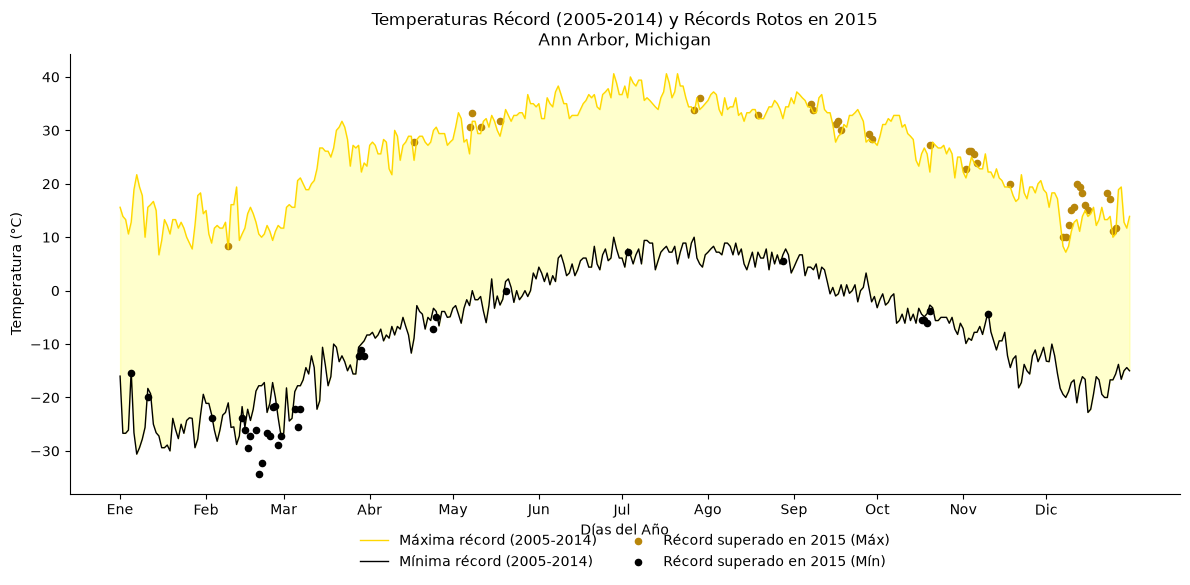

In [28]:
#Creamos la grafica
plt.figure(figsize=(12, 6))

# Dibujamos las líneas de temperaturas máximas(roja) y minimas (azules)
plt.plot(max_0514.values, color='gold', linewidth=1, label='Máxima récord (2005-2014)')
plt.plot(min_0514.values, color='black', linewidth=1, label='Mínima récord (2005-2014)')

# Sombreamos el área entre la línea mínima y máxima
plt.fill_between(range(len(max_0514)), min_0514.values, max_0514.values, color='yellow', alpha=0.2)

# Buscamos las posiciones donde se rompieron los récords en 2015
pos_max = [max_0514.index.get_loc(dia) for dia in record_max_15.index]
pos_min = [min_0514.index.get_loc(dia) for dia in record_min_15.index]

# Dibujamos los puntos rojos de superación de récord máximo y azules los de record minimo
plt.scatter(pos_max, record_max_15.values, color='darkgoldenrod', s=20, label='Récord superado en 2015 (Máx)')
plt.scatter(pos_min, record_min_15.values, color='black', s=20, label='Récord superado en 2015 (Mín)')

# Mejoramos la estetica de visualizacion con titulos y nombres en los ejes
plt.title('Temperaturas Récord (2005-2014) y Récords Rotos en 2015\nAnn Arbor, Michigan', fontsize=12)
plt.ylabel('Temperatura (°C)')
plt.xlabel('Días del Año')

# Ponemos las marcas del eje X al inicio de cada mes aproximado
meses_pos = [0, 31, 59, 90, 120, 151, 181, 212, 243, 273, 304, 334]
meses_nombres = ['Ene', 'Feb', 'Mar', 'Abr', 'May', 'Jun', 'Jul', 'Ago', 'Sep', 'Oct', 'Nov', 'Dic']
plt.xticks(meses_pos, meses_nombres)

# Quitamos líneas innecesarias
ax = plt.gca()
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Leyenda explicativa
plt.legend(loc='lower center', bbox_to_anchor=(0.5, -0.2), ncol=2, frameon=False)

# Mostrar el gráfico
plt.tight_layout()
plt.show()